In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511058/notebook

Mounted at /content/drive
/content/drive/MyDrive/simuteh-2330511058/notebook


In [ ]:
import os
print(os.getcwd())
print(os.listdir("../src"))
print(len(os.listdir("../data/sintetis/citra")))

/content/drive/MyDrive/simuteh-2330511058/notebook
['buat_dataset_sintetis.py', 'utils_cv.py']
60


Kode 1.1 Uji Lingkungan dan Stuktur Larik Citra

OpenCV 5.0.0 | NumPy 2.1.3 | scikit-image 0.25.2
shape: (480, 640, 3) dtype: uint8
min-maks: 0 255
piksel (y=100, x=200) dalam urutan BGR: [168 202 198]


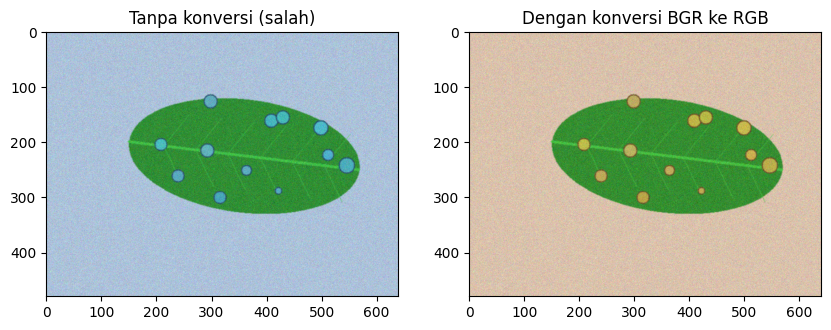

In [ ]:
import sys
sys.path.append("../src") # agar utils_cv dapat diimpor dari notebook/
import cv2, numpy as np, skimage, matplotlib.pyplot as plt
from utils_cv import baca, tampil
print("OpenCV", cv2.__version__, "| NumPy", np.__version__,
      "| scikit-image", skimage.__version__)
img = baca("../data/sintetis/citra/teh_041.png")
print("shape:", img.shape, "dtype:", img.dtype)
print("min-maks:", img.min(), img.max())
print("piksel (y=100, x=200) dalam urutan BGR:", img[100, 200])
# tampilkan citra TANPA dan DENGAN konversi BGR ke RGB
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(img); plt.title("Tanpa konversi (salah)")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Dengan konversi BGR ke RGB"); plt.savefig("../hasil/b1_bgr_rgb.png")

## P1 : **Problem statement**

**Bagi petugas sortir** di kelompok tani teh rakyat Kabupaten Sukabumi **yang menghadapi** penilaian bercak daun secara manual yang lambat dan tidak seragam, terutama saat cahaya di lokasi sortir tidak merata atau bercaknya masih kecil, **kami membangun SIMUTEH**, sistem berbasis visi komputer, **yang menerima** foto daun teh berwarna di atas nampan sortir dari kamera telepon genggam (pada tahap ini berupa citra sintetis berukuran 640 × 480 piksel, 3 kanal warna, 8 bit) **dan menghasilkan** kelas mutu (Sehat, Bercak Ringan, atau Bercak Berat) beserta persentase luas bercak terhadap luas daun, **sehingga** petugas memperoleh pertimbangan yang lebih cepat dan konsisten, sementara keputusan akhir tetap di tangan petugas.